In [162]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.stats import f_oneway
import seaborn as sns

pd.options.display.float_format = '{:,.2f}'.format

In [163]:
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 20)
pd.set_option("display.width", 240)

np.random.seed(1)

data = np.random.rand(200, 20)

colonnes = [f"colonne {i}" for i in range(1, 21)]

df = pd.DataFrame(data, columns=colonnes)

print(df)

     colonne 1  colonne 2  colonne 3  colonne 4  colonne 5  colonne 6  ...  colonne 15  colonne 16  colonne 17  colonne 18  colonne 19  colonne 20
0         0.42       0.72       0.00       0.30       0.15       0.09  ...        0.03        0.67        0.42        0.56        0.14        0.20
1         0.80       0.97       0.31       0.69       0.88       0.89  ...        0.69        0.32        0.69        0.83        0.02        0.75
2         0.99       0.75       0.28       0.79       0.10       0.45  ...        0.49        0.05        0.57        0.15        0.59        0.70
3         0.10       0.41       0.69       0.41       0.05       0.54  ...        0.40        0.17        0.93        0.35        0.75        0.73
4         0.88       0.62       0.75       0.35       0.27       0.90  ...        0.41        0.24        0.90        0.57        0.00        0.62
..         ...        ...        ...        ...        ...        ...  ...         ...         ...         ...        

### DataFrame = Tableau 2 dimension composée de plusieurs Series
### Series = Tableau 1 dimension contenant le meme type pour chaque donnée
### Index = Valeur unique permettant de lier, cet valeur a une donnée du tableau pour recuperer les données plus rapidement

# 2. CHARGEMENT DES DONNÉES

Chargez chaque feuille de calcul du fichier Excel dans des DataFrame séparés pour des variables nommées respectivement :

In [164]:
file = "CC-AIBD-DataAnalyse-donnees.xlsx"

excel = pd.ExcelFile(file)
nom_feuille = excel.sheet_names

print(nom_feuille)


orders = pd.read_excel(file, sheet_name = nom_feuille[0])
territories = pd.read_excel(file, sheet_name = nom_feuille[1])
sales = pd.read_excel(file, sheet_name = nom_feuille[2])
resellers = pd.read_excel(file, sheet_name = nom_feuille[3])
dates = pd.read_excel(file, sheet_name = nom_feuille[4])
products = pd.read_excel(file, sheet_name = nom_feuille[5])
customers = pd.read_excel(file, sheet_name = nom_feuille[6])

dfs = {
    "orders": orders,
    "territories": territories,
    "sales": sales,
    "resellers": resellers,
    "dates": dates,
    "products": products,
    "customers": customers
}


['Sales Order_data', 'Sales Territory_data', 'Sales_data', 'Reseller_data', 'Date_data', 'Product_data', 'Customer_data']


Affichez les cinq premières lignes de chaque DataFrame et vérifiez-en également les types de colonnes.

In [165]:
for nom, df in dfs.items():
    print(f"\n--- {nom} ---")
    display(df.head(5))
    print("Types des colonnes :")
    print(df.dtypes)


--- orders ---


,Channel,SalesOrderLineKey,Sales Order,Sales Order Line
0,Reseller,43659001,SO43659,SO43659 - 1
1,Reseller,43659002,SO43659,SO43659 - 2
2,Reseller,43659003,SO43659,SO43659 - 3
3,Reseller,43659004,SO43659,SO43659 - 4
4,Reseller,43659005,SO43659,SO43659 - 5


Types des colonnes :
Channel                str
SalesOrderLineKey    int64
Sales Order            str
Sales Order Line       str
dtype: object

--- territories ---


,SalesTerritoryKey,Region,Country,Group
0,1,Northwest,United States,North America
1,2,Northeast,United States,North America
2,3,Central,United States,North America
3,4,Southwest,United States,North America
4,5,Southeast,United States,North America


Types des colonnes :
SalesTerritoryKey    int64
Region                 str
Country                str
Group                  str
dtype: object

--- sales ---


...

Types des colonnes :
DateKey                    int64
Date              datetime64[us]
Fiscal Year                  str
Fiscal Quarter               str
Month                        str
Full Date                    str
MonthKey                   int64
dtype: object

--- products ---


,ProductKey,SKU,Product,Standard Cost,Color,List Price,Model,Subcategory,Category
0,210,FR-R92B-58,HL Road Frame - ...,868.63,Black,"1,431.50",HL Road Frame,Road Frames,Components
1,211,FR-R92R-58,HL Road Frame - ...,868.63,Red,"1,431.50",HL Road Frame,Road Frames,Components
2,212,HL-U509-R,Sport-100 Helmet...,12.03,Red,33.64,Sport-100,Helmets,Accessories
3,213,HL-U509-R,Sport-100 Helmet...,13.88,Red,33.64,Sport-100,Helmets,Accessories
4,214,HL-U509-R,Sport-100 Helmet...,13.09,Red,34.99,Sport-100,Helmets,Accessories


Types des colonnes :
ProductKey         int64
SKU                  str
Product              str
Standard Cost    float64
Color                str
List Price       float64
Model                str
Subcategory          str
Category             str
dtype: object

--- customers ---


,CustomerKey,Customer ID,Customer,City,State-Province,Country-Region,Postal Code
0,-1,[Not Applicable],[Not Applicable],[Not Applicable],[Not Applicable],[Not Applicable],[Not Applicable]
1,11000,AW00011000,Jon Yang,Rockhampton,Queensland,Australia,4700
2,11001,AW00011001,Eugene Huang,Seaford,Victoria,Australia,3198
3,11002,AW00011002,Ruben Torres,Hobart,Tasmania,Australia,7001
4,11003,AW00011003,Christy Zhu,North Ryde,New South Wales,Australia,2113


Types des colonnes :
CustomerKey       int64
Customer ID         str
Customer            str
City                str
State-Province      str
Country-Region      str
Postal Code         str
dtype: object


Affichez des informations de base sur les DataFrame via les méthodes info() et describe() pour obtenir des informations sur la taille, les types de données et les valeurs manquantes dans chaque DataFrame .

In [166]:
for nom, df in dfs.items():
    print(f"\n--- {nom} ---")
    print(f"\n--- Info ---")
    df.info()

    print(f"\n--- Description ---")
    print(df.describe())

    print(f"\n--- Valeur manquantes ---")
    print(df.isna().sum())




--- orders ---

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 121253 entries, 0 to 121252
Data columns (total 4 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   Channel            121253 non-null  str  
 1   SalesOrderLineKey  121253 non-null  int64
 2   Sales Order        121253 non-null  str  
 3   Sales Order Line   121253 non-null  str  
dtypes: int64(1), str(3)
memory usage: 6.7 MB

--- Description ---
       SalesOrderLineKey
count         121,253.00
mean       57,826,421.61
std         9,009,990.13
min        43,659,001.00
25%        49,879,048.00
50%        57,028,005.00
75%        65,490,001.00
max        75,123,003.00

--- Valeur manquantes ---
Channel              0
SalesOrderLineKey    0
Sales Order          0
Sales Order Line     0
dtype: int64

--- territories ---

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 4 columns):
 #   Column             Non-Null Count 

Affichez des informations de distribution (dispersion) du coût standard des produits du catalogue. </br>
Affichez la médiane, l'écart-type et la variance. Calculez les mêmes informations, mais cette fois-ci par catégorie de produit( Category ).

In [167]:
print(products['Standard Cost'].agg(['median', 'std', 'var']))

print(products.groupby('Category')['Standard Cost'].agg(['median', 'std', 'var']))


median       204.63
std          497.08
var      247,085.43
Name: Standard Cost, dtype: float64
             median    std        var
Category                             
Accessories   11.22  13.13     172.34
Bikes        713.08 552.41 305,153.73
Clothing      26.18  12.42     154.37
Components   187.16 280.64  78,756.88


# 3. NETTOYAGE DES DONNÉES

Assurez-vous dans tous les DataFrames qu'il n'existe aucune cellule laissée vide. </br>
Si ce n'est pas le cas, affichez les identifiants des colonnes contenant des valeurs vides. Remplacez également ces valeurs par une valeur de repli si besoin.

In [168]:
for nom, df in dfs.items():
    colonnes_vides = df.columns[df.isnull().any()].tolist()

    if colonnes_vides:
        print(nom, ":", colonnes_vides)

        for colonne in colonnes_vides:
            if df[colonne].dtype == "object":
                df[colonne] = df[colonne].fillna("Inconnu")
            else:
                df[colonne] = df[colonne].fillna(0)
    else:
        print(nom, ": aucune valeur vide")


orders : aucune valeur vide
territories : aucune valeur vide
sales : ['ShipDateKey']
resellers : aucune valeur vide
dates : aucune valeur vide
products : ['Color']
customers : aucune valeur vide


In [169]:
colonnes_vides = sales.columns[sales.isnull().any()].tolist()
nom = "sales"
if colonnes_vides:
    print(sales, ":", colonnes_vides)

    for colonne in colonnes_vides:
        if sales[colonne].dtype == "object":
            sales[colonne] = sales[colonne].fillna("Inconnu")
        else:
            sales[colonne] = sales[colonne].fillna(0)
else:
    print(nom, ": aucune valeur vide")

sales : aucune valeur vide


Vérifiez dans les ventes que le total des ventes est correct, notamment lorsque la valeur de remise (discount) est non nulle. </br>
Créez une colonne Price ratio calculant le multiplicateur entre le prix affiché et le coût du produit.

In [196]:
for index, ligne in sales.iterrows():
    total_attendu = round(ligne["Order Quantity"] * ligne["Unit Price"] * (1 - ligne["Unit Price Discount Pct"] / 100),5)

    if not math.isclose(ligne["Sales Amount"], total_attendu, abs_tol = 0.001) :
        print("Ligne", index, ": incorrecte")
        print("Sales Amount :", ligne["Sales Amount"])
        print("Total attendu :", total_attendu)
        print("Discount :", ligne["Unit Price Discount Pct"])

        print("Recalcul du discount")
        remise_attendu = round((1 - ligne["Sales Amount"] / (ligne["Order Quantity"] * ligne["Unit Price"])) * 100)
        sales.loc[index, "Unit Price Discount Pct"] = remise_attendu
        print("Nouveau discount", remise_attendu)
        print()

In [171]:
sales["Price ratio"] = sales["Unit Price"] / sales["Product Standard Cost"]

Créez une colonne Line number dans orders extrayant le numéro de ligne de la colonne Sales Order Line . </br>
Traitez et convertissez les colonnes qui ne semblent pas avoir un type de données correct inféré pour l'analyse.</br>
Créez une colonne Margin représentant la marge entre les ventes et le coût total.

In [172]:
orders["Line number"] = orders["Sales Order Line"].str.extract(r"(\d+)$").astype(int)

In [173]:
sales["Margin"] = sales["Sales Amount"] - sales["Total Product Cost"]

# 4. Analyse Exploratoire des Données (EDA)

Affichez le total des ventes, réparti par territoire en utilisant des graphiques à barres. </br>
L'intitulé des barres doit être horizontal, et représenter le Country du territoire ainsi que la Region sur une seconde ligne. </br>
Sauvegardez le diagramme dans un fichier au format PNG.

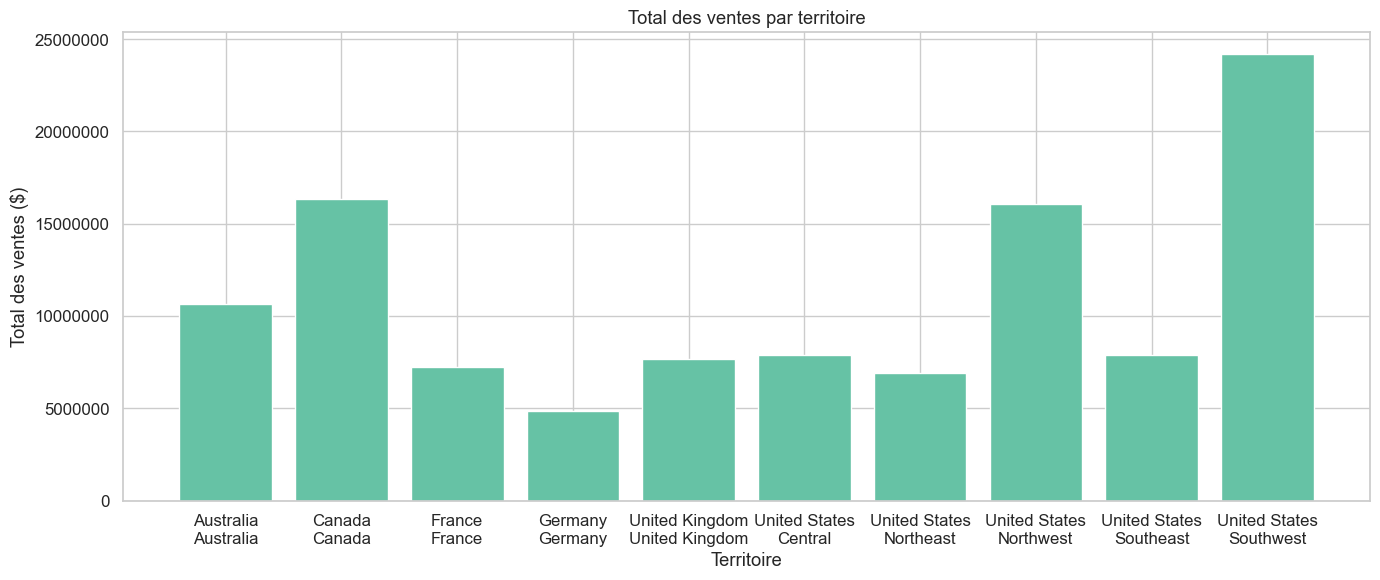

In [174]:
df = sales.merge(territories, on="SalesTerritoryKey", how="left")

ventes_territoire = (
    df.groupby(["Country", "Region"], as_index=False)["Sales Amount"]
      .sum()
)

ventes_territoire["Territoire"] = (
    ventes_territoire["Country"] + "\n" + ventes_territoire["Region"]
)

# Graphique
plt.figure(figsize=(14, 6))
plt.ticklabel_format(style='plain', axis='both')
plt.bar(
    ventes_territoire["Territoire"],
    ventes_territoire["Sales Amount"]
)

plt.title("Total des ventes par territoire")
plt.xlabel("Territoire")
plt.ylabel("Total des ventes ($)")

# Intitulés horizontaux
plt.xticks(rotation=0)

plt.tight_layout()

# Sauvegarde en PNG
plt.savefig("total_ventes_territoire.png", format="png", dpi=300)

plt.show()


Affichez le total des ventes par Model de produit via une visualisation dans un graphique adapté (secteur ou barres). </br>
Sauvegardez également le diagramme dans un fichier au format PNG.

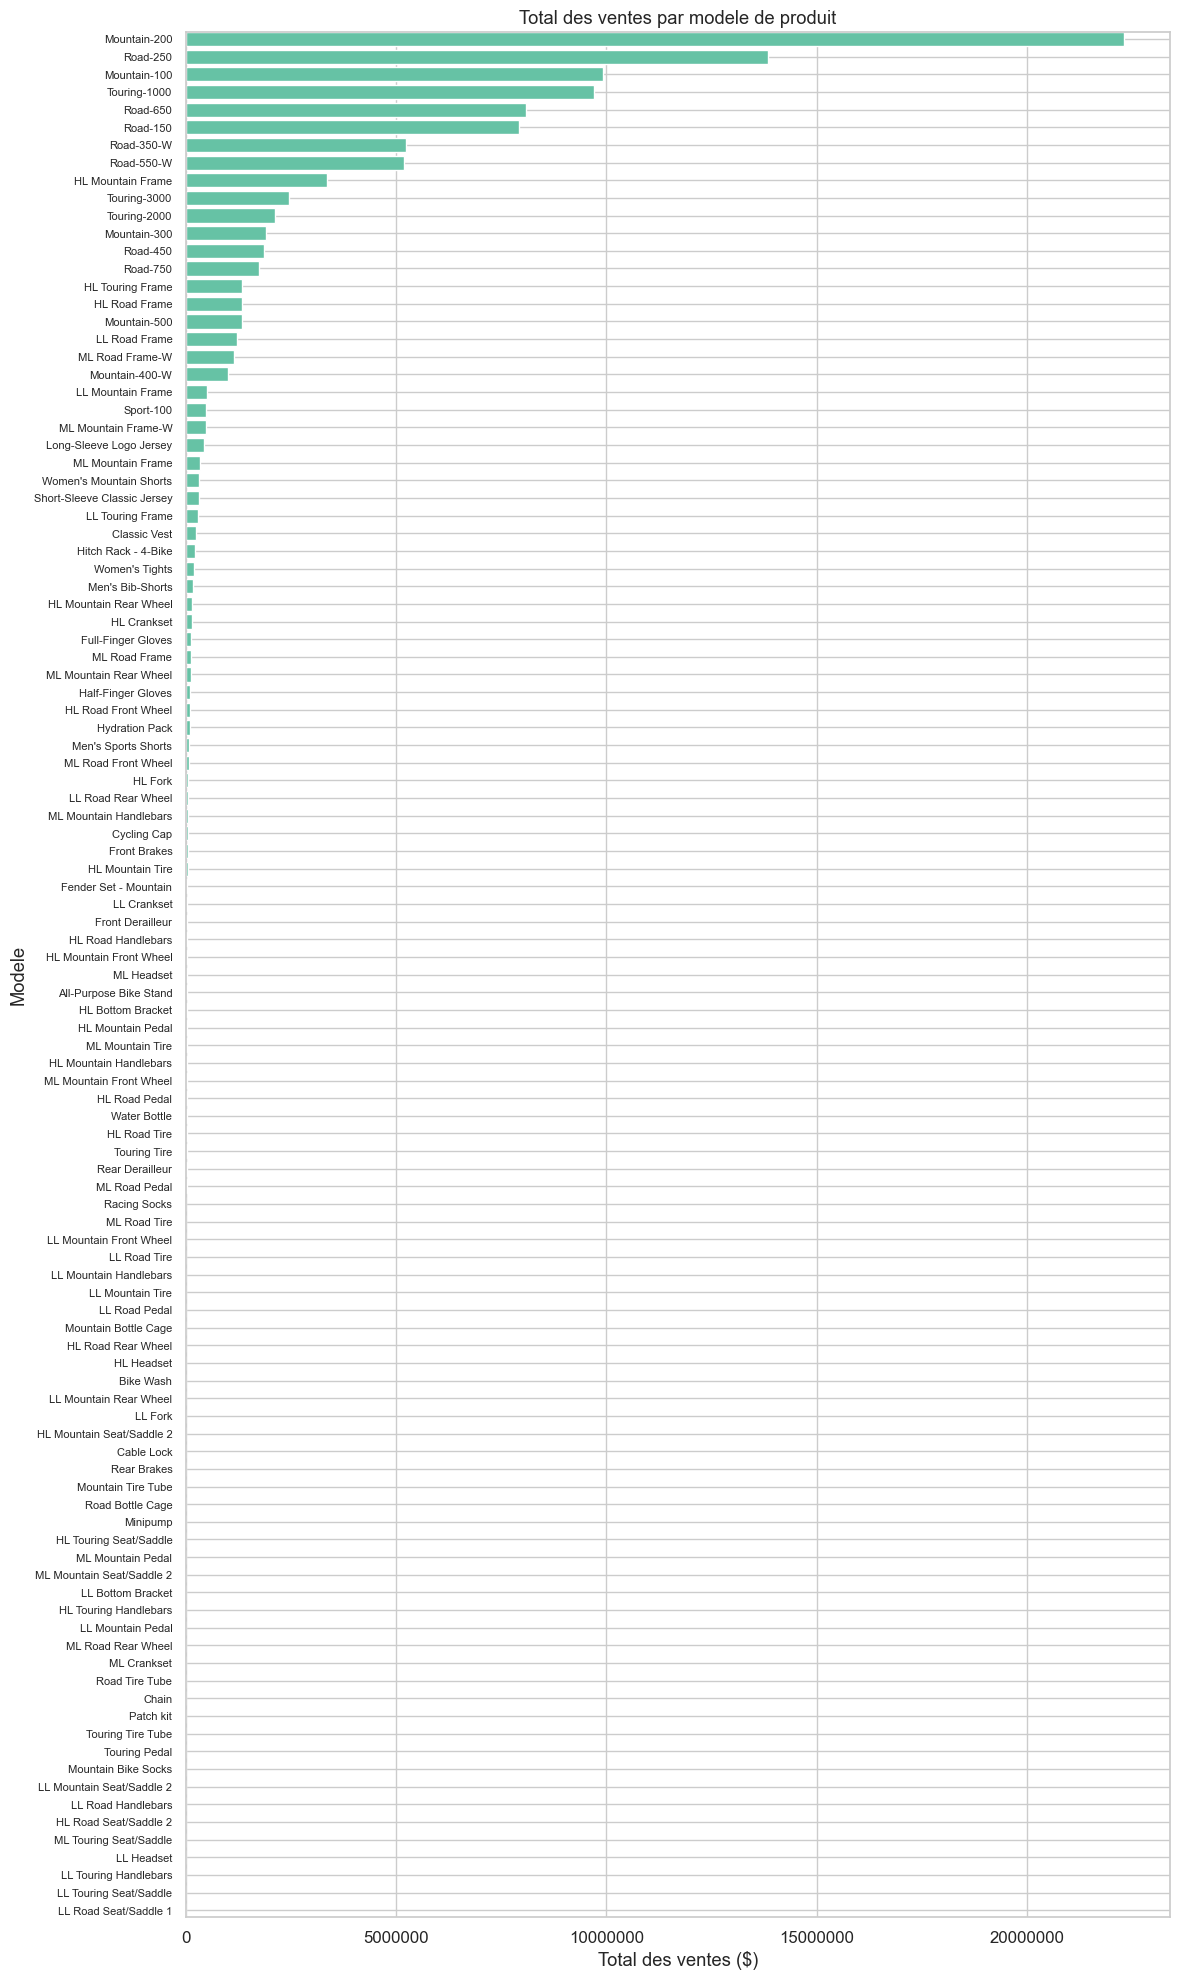

In [175]:
df = sales.merge(products, on="ProductKey", how="left")

ventes_model = (
    df.groupby("Model", as_index=False)["Sales Amount"]
      .sum()
      .sort_values("Sales Amount", ascending=True)
)


# Graphique
plt.figure(figsize=(12, 20))

plt.barh(
    ventes_model["Model"],
    ventes_model["Sales Amount"]
)
plt.title("Total des ventes par modele de produit")
plt.xlabel("Total des ventes ($)")
plt.ylabel("Modele")

# Intitulés horizontaux
plt.yticks(fontsize=8)
plt.xticks(rotation=0)

plt.ticklabel_format(style='plain', axis='x')
plt.margins(y=0)

plt.tight_layout()

# Sauvegarde en PNG
plt.savefig("total_ventes_model.png", format="png", dpi=300)

plt.show()


Explorez les ventes par jour et identifiez les tendances saisonnières potentielles; créez des colonnes avec des moyennes de ventes lissées sur 7, et sur 30 jours. </br>
Affichez des graphiques en lignes pour voir ces tendances.

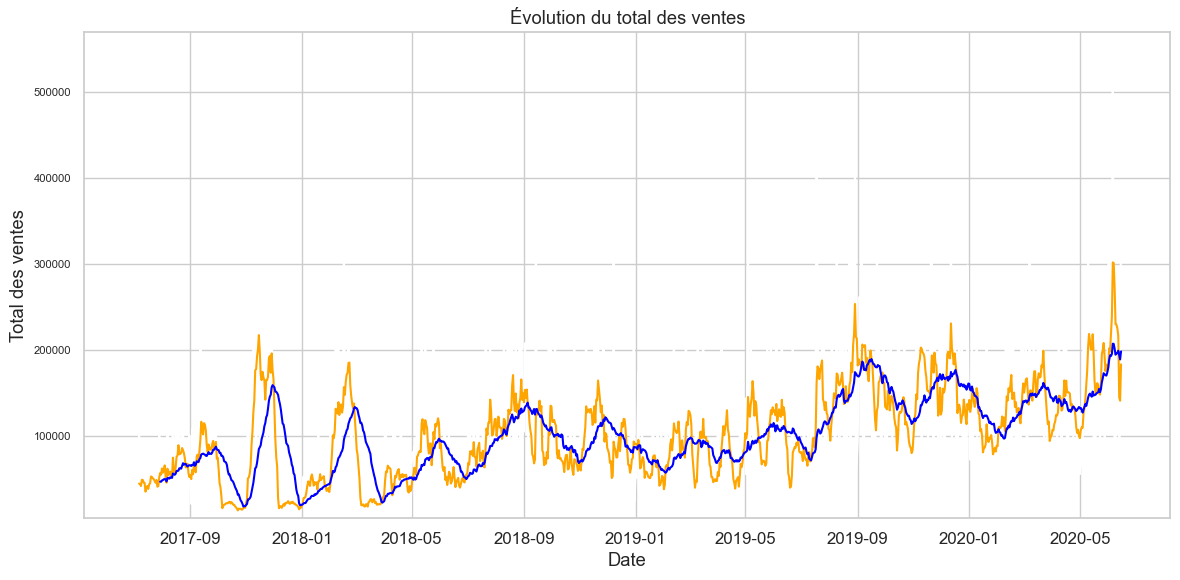

In [176]:
df = sales.merge(dates, left_on="OrderDateKey", right_on="DateKey", how="left")

ventes_date = (
    df.groupby("Date", as_index=False)["Sales Amount"]
      .sum()
)


ventes_date["Moyenne 7 jours"] = ventes_date["Sales Amount"].rolling(7).mean()
ventes_date["Moyenne 30 jours"] = ventes_date["Sales Amount"].rolling(30).mean()

# Graphique
plt.figure(figsize=(12, 6))

plt.plot(ventes_date["Date"],ventes_date["Sales Amount"],color= "white" ,label="Ventes par jour")
plt.plot(ventes_date["Date"],ventes_date["Moyenne 7 jours"], color= "orange" , label="Moyenne ventes par 7 jour")
plt.plot(ventes_date["Date"],ventes_date["Moyenne 30 jours"], color= "blue", label="Moyenne ventes par 30 jour")

plt.title("Évolution du total des ventes")
plt.xlabel("Date")
plt.ylabel("Total des ventes")

# Intitulés horizontaux
plt.yticks(fontsize=8)
plt.xticks(rotation=0)
plt.margins(y=0)

plt.tight_layout()

plt.show()

Générez des tableaux croisés dynamiques (pivot tables) pour analyser les ventes par différentes dimensions (par exemple, somme des ventes par produit et par territoire).

In [177]:
df = sales.merge(territories, on="SalesTerritoryKey", how="left")
df = df.merge(products, on="ProductKey", how="left")

pivot_country = pd.pivot_table(
    df,
    values="Sales Amount",
    index="Model",
    columns="Country",
    aggfunc="sum"
)

pivot_region = pd.pivot_table(
    df,
    values="Sales Amount",
    index="Model",
    columns="Region",
    aggfunc="sum"
)


print(pivot_country)
print(pivot_region)

Country               Australia     Canada     France    Germany  United Kingdom  United States
Model                                                                                          
All-Purpose Bike ...  10,335.00   5,088.00   3,021.00   3,180.00        4,452.00      13,515.00
Bike Wash              2,286.42   3,268.60   1,459.58   1,378.69        1,587.97       8,425.73
Cable Lock                  NaN   4,210.24   1,050.00        NaN          735.00      10,229.98
Chain                    850.08   1,141.54   1,231.65     522.19          660.25       4,972.00
Classic Vest          21,065.62  48,102.10  23,613.38  23,050.42       22,036.20     121,620.66
...                         ...        ...        ...        ...             ...            ...
Touring-2000         270,668.58 211,383.90 235,781.98 222,381.21      212,994.31     979,901.90
Touring-3000         347,310.30 277,022.75 284,640.45 309,472.65      239,422.65     989,508.46
Water Bottle           4,314.35   4,382.

# 5. Analyse Statistique des Données

Affichez les informations statistiques classiques des ventes (moyenne, médiane, écart-type, minimum, maximum, premier quartile et troisième quartile) pour chaque territoire.

In [178]:
df = sales.merge(territories, on="SalesTerritoryKey", how="left")

df.groupby(["Country", "Region"])["Sales Amount"].describe()

count     mean      std  min    25%    50%      75%       max
Country        Region                                                                          
Australia      Australia      15,058.00   707.62 1,119.90 2.29   8.99  35.00 1,120.49 17,616.37
Canada         Canada         19,064.00   857.94 1,688.14 1.37  26.72 127.80   890.82 23,020.13
France         France          9,088.00   797.93 1,583.30 2.29  21.49  64.79   923.39 23,667.85
Germany        Germany         7,464.00   653.58 1,263.61 1.37   8.99  35.00   769.49 19,930.83
United Kingdom United Kingdom 10,426.00   735.73 1,402.64 1.37   9.99  53.99   890.82 22,422.18
United States  Central         5,832.00 1,356.14 2,221.75 1.37 125.42 469.79 1,619.97 27,055.76
               Northeast       5,836.00 1,189.06 1,753.82 1.37 136.76 449.94 1,430.44 14,880.00
               Northwest      16,865.00   953.75 1,916.08 1.37  24.29  86.52 1,120.49 21,101.79
               Southeast       5,976.00 1,318.55 2,175.63 1.37 115.36 445.41 1,471.70 24,938.48
               Southwest      25,644.00   943.09 1,746.77 1.37  28.84 149.03 1,200.31 27,893.62

Calculez la corrélation entre différentes variables : </br>
-Entre les ventes totales et les profits. </br>
-Entre le coût total et la marge.

In [179]:
print("Corrélation entre les ventes et les profits :", df["Sales Amount"].corr(df["Sales Amount"] - df["Total Product Cost"]))

print("Corrélation entre le coût total et la marge :", df["Total Product Cost"].corr(df["Margin"]))

Corrélation entre les ventes et les profits : 0.2005096901833972
Corrélation entre le coût total et la marge : -0.03584048246469346


Identifiez les territoires et produits les plus performants en termes de ventes.

In [180]:
# Total des ventes par territoire
df = sales.merge(territories, on="SalesTerritoryKey", how="left")

ventes_territoire = (
    df.groupby(["Country", "Region"])["Sales Amount"]
      .sum()
      .sort_values(ascending=False)
)

print(ventes_territoire.head(5))

# Total des ventes par produit
df = sales.merge(products, on="ProductKey", how="left")

ventes_model = (
    df.groupby("Product", as_index=False)["Sales Amount"]
      .sum()
      .sort_values("Sales Amount", ascending=False)
)

pd.set_option("display.max_colwidth", None)
print(ventes_model.head(5))

Country        Region   
United States  Southwest   24,184,609.60
Canada         Canada      16,355,770.46
United States  Northwest   16,084,942.55
Australia      Australia   10,655,335.96
United States  Central      7,909,009.01
Name: Sales Amount, dtype: float64
                     Product  Sales Amount
153   Mountain-200 Black, 38  4,400,592.80
154   Mountain-200 Black, 42  4,009,494.76
156  Mountain-200 Silver, 38  3,693,678.03
157  Mountain-200 Silver, 42  3,438,478.86
158  Mountain-200 Silver, 46  3,434,256.94


Effectuez des tests statistiques pour vérifier les hypothèses, par exemple, l'écart type des ventes par territoire.

In [181]:
df = sales.merge(territories, on="SalesTerritoryKey", how="left")

ecart_type_territoire = (
    df.groupby(["Country", "Region"])["Sales Amount"]
      .std()
      .sort_values(ascending=False)
)

print(ecart_type_territoire)

groupes = [
    groupe["Sales Amount"].dropna().values
    for _, groupe in df.groupby(["Country", "Region"])
]

statistique, p_value = f_oneway(*groupes)

print("Statistique F :", statistique)
print("p-value :", p_value)

# p-value étant inférieure à 0,05, ventes moyennes diffèrent significativement selon les territoires.

Country         Region        
United States   Central          2,221.75
                Southeast        2,175.63
                Northwest        1,916.08
                Northeast        1,753.82
                Southwest        1,746.77
Canada          Canada           1,688.14
France          France           1,583.30
United Kingdom  United Kingdom   1,402.64
Germany         Germany          1,263.61
Australia       Australia        1,119.90
Name: Sales Amount, dtype: float64
Statistique F : 167.05885810606364
p-value : 0.0


# 6. Visualisation Avancée avec Matplotlib

Affichez un nuage de points (scatter) pour explorer les relations entre les variables (total des ventes en x, marge en y, et prix unitaire pour l'intensité des points).


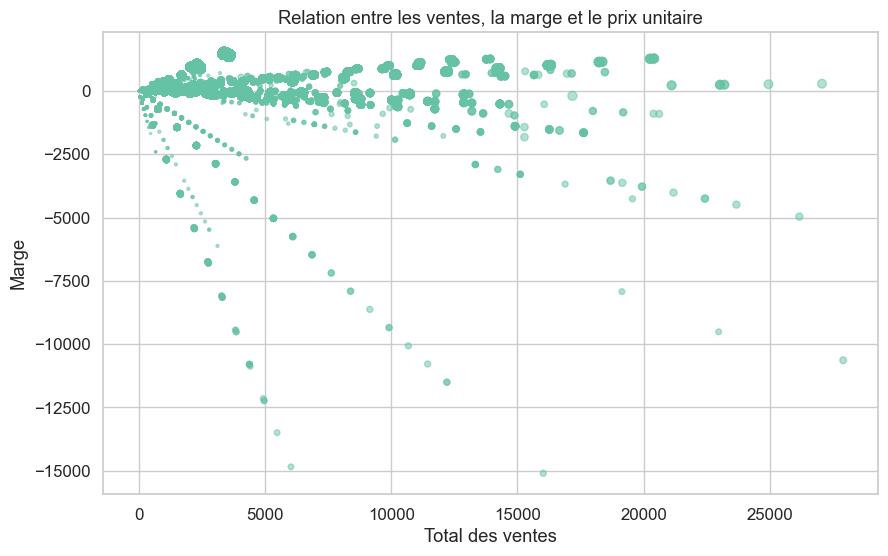

In [182]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Sales Amount"],
    df["Margin"],
    s=df["Unit Price"] / 50,
    alpha=0.5
)

plt.xlabel("Total des ventes")
plt.ylabel("Marge")
plt.title("Relation entre les ventes, la marge et le prix unitaire")

plt.show()

Créez des diagrammes à moustache (box plot) pour analyser la distribution en quartiles des ventes. Une boîte par territoire, valeurs de boîte par modèle de produit.

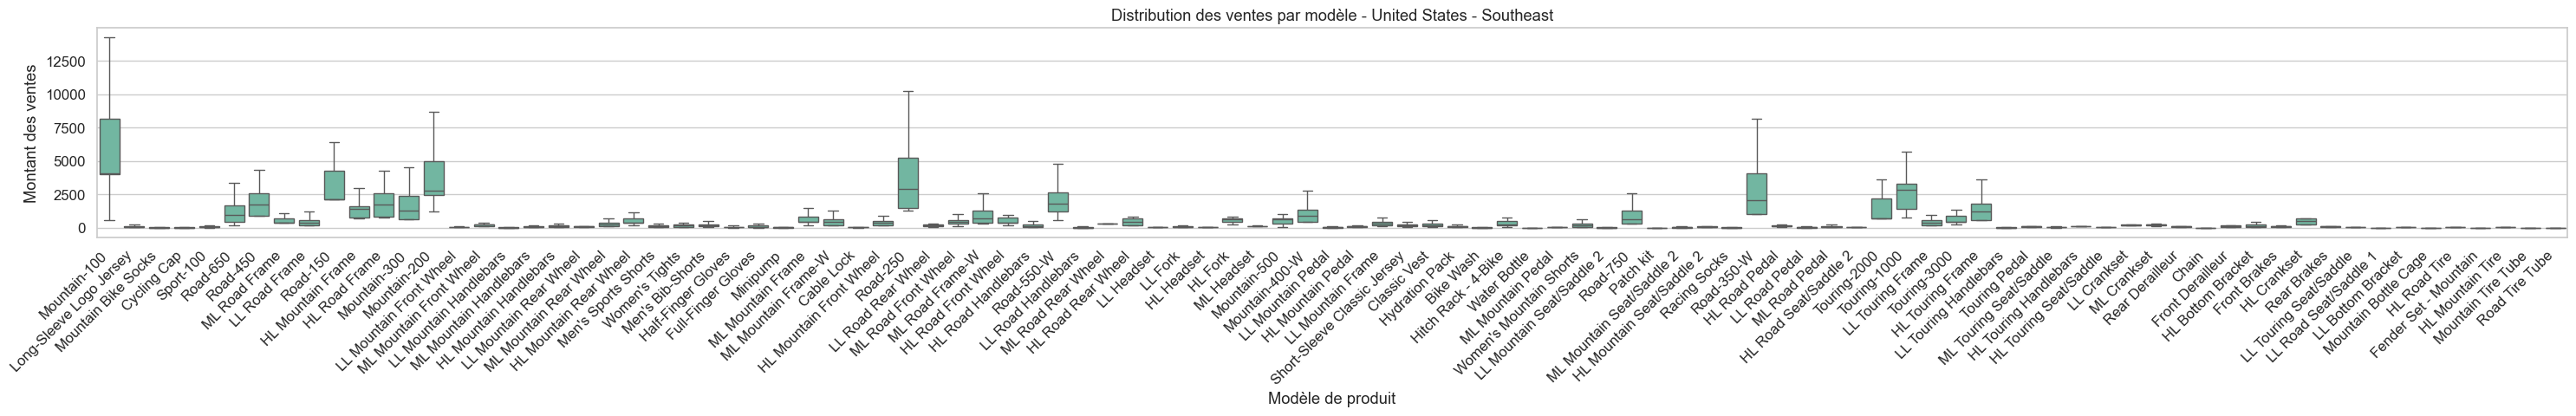

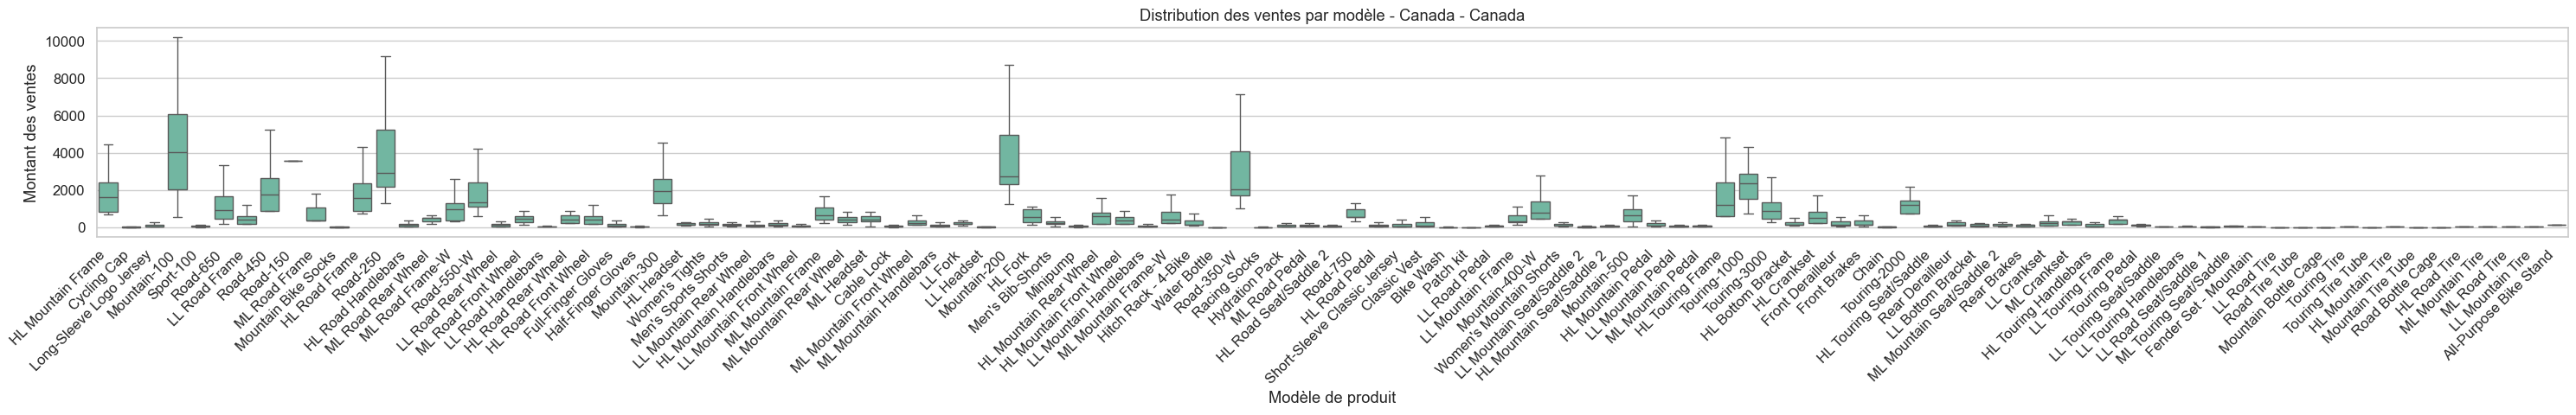

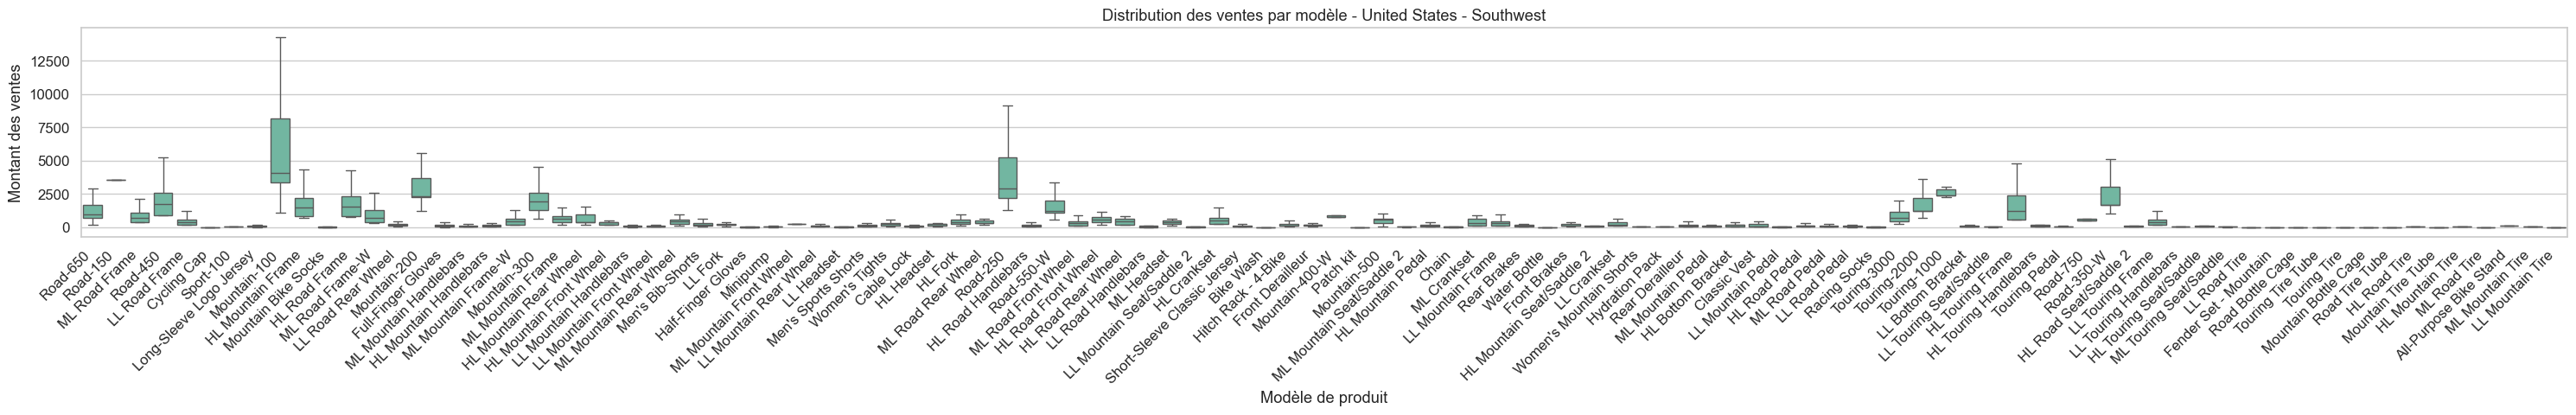

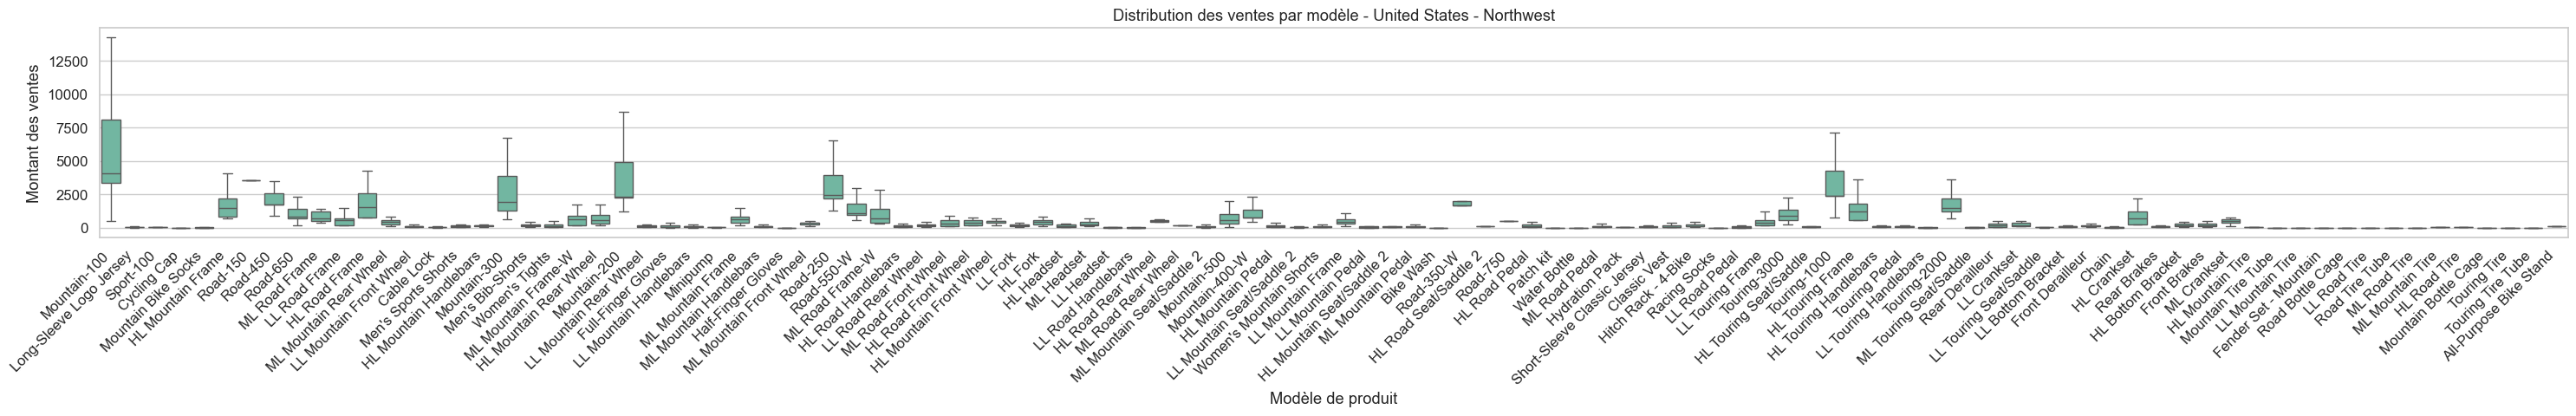

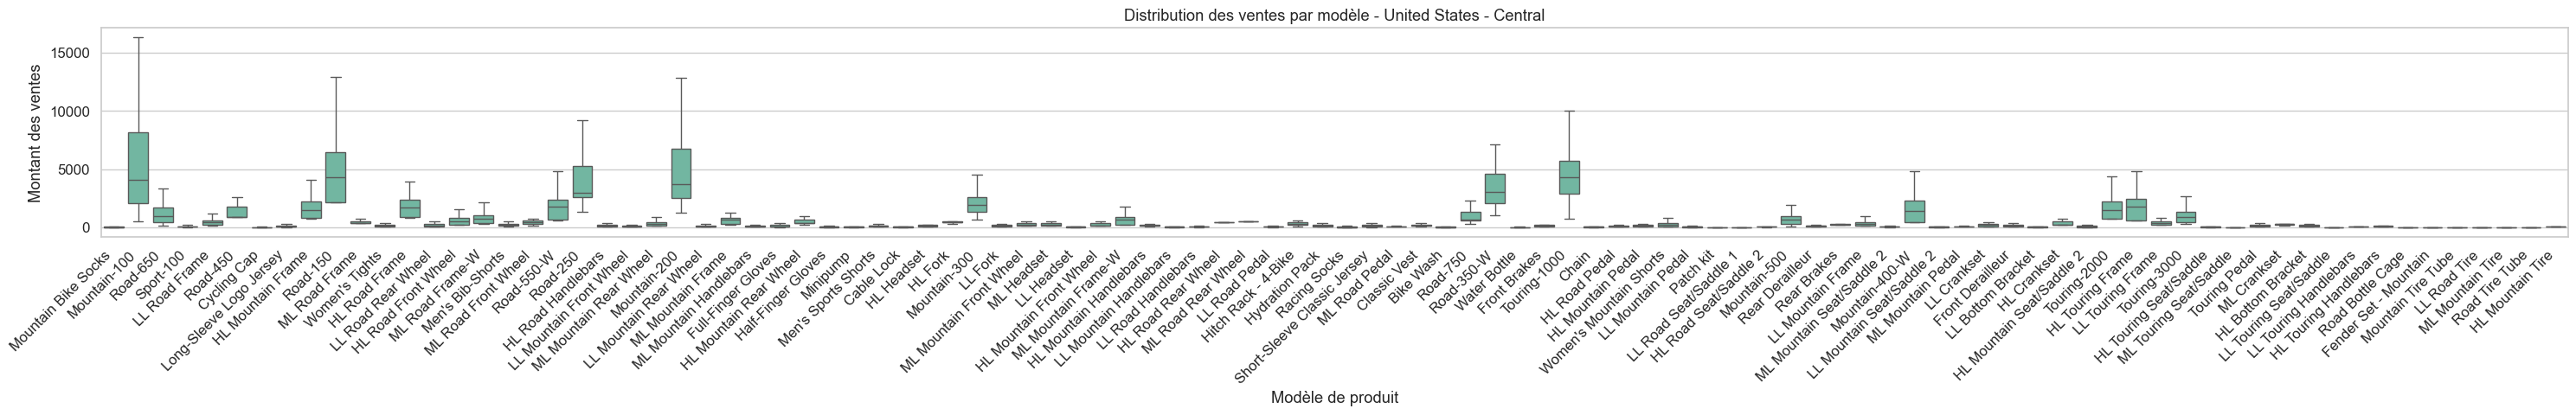

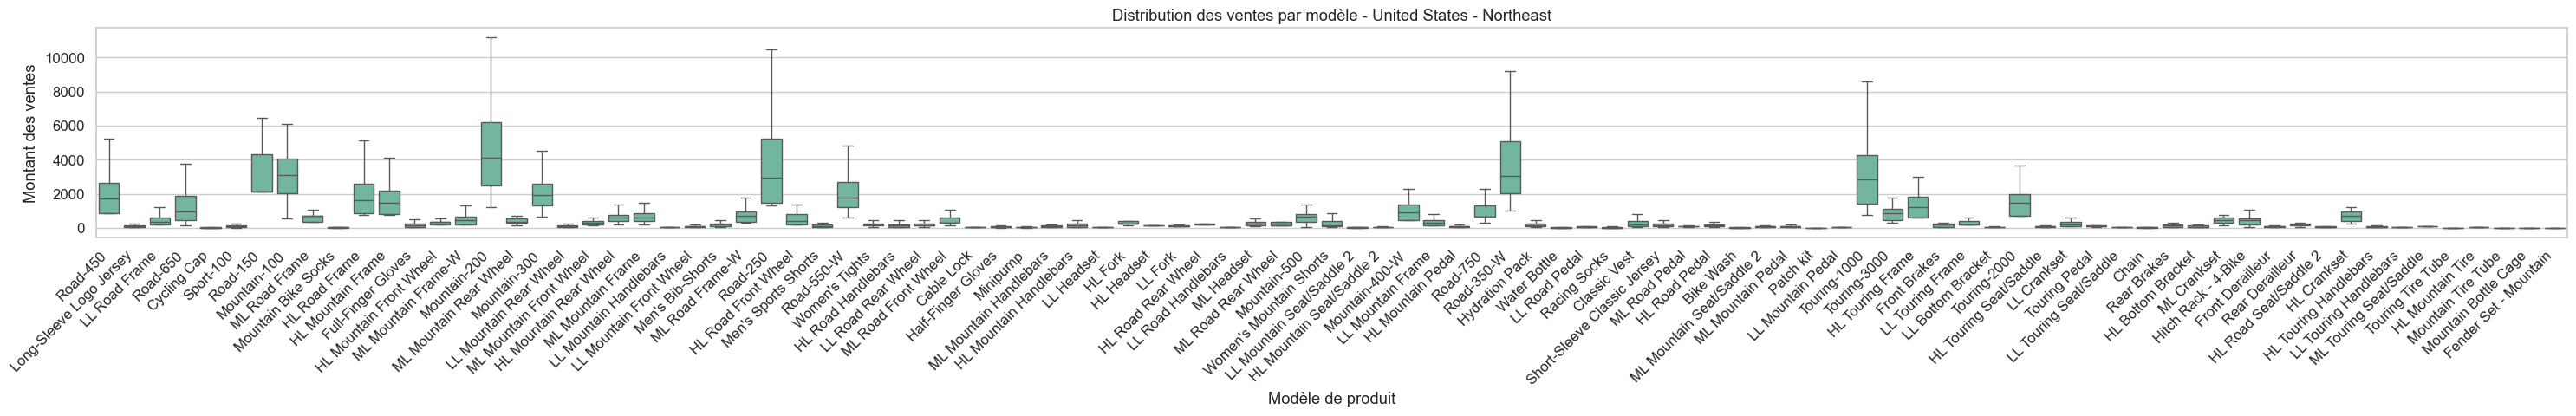

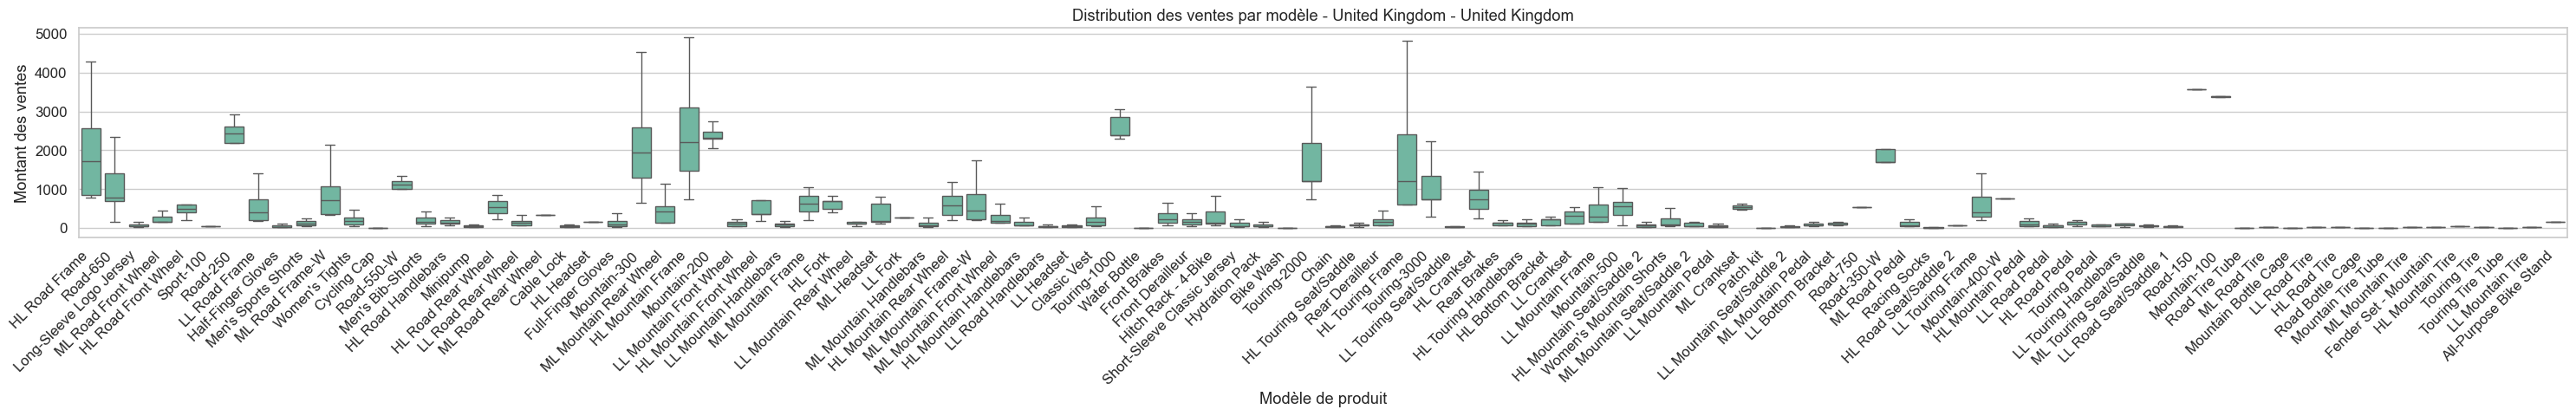

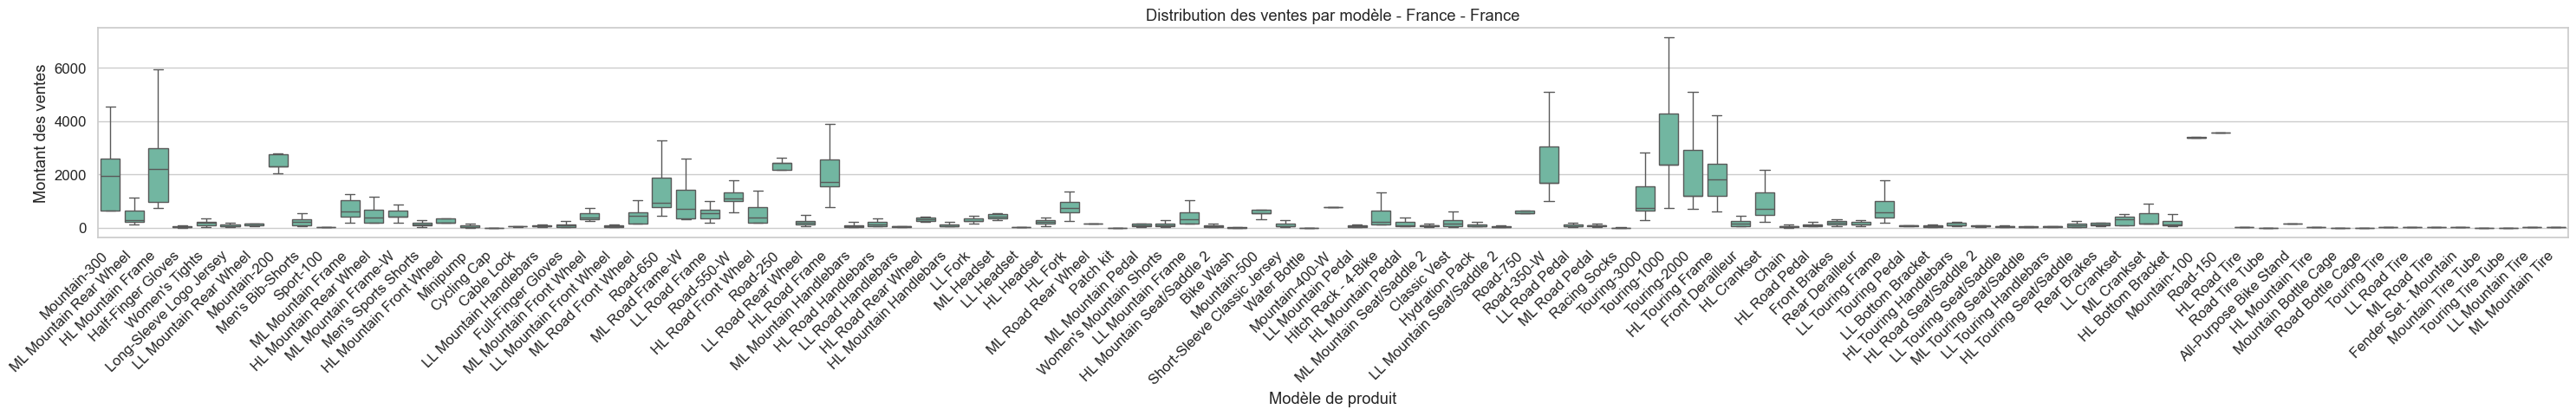

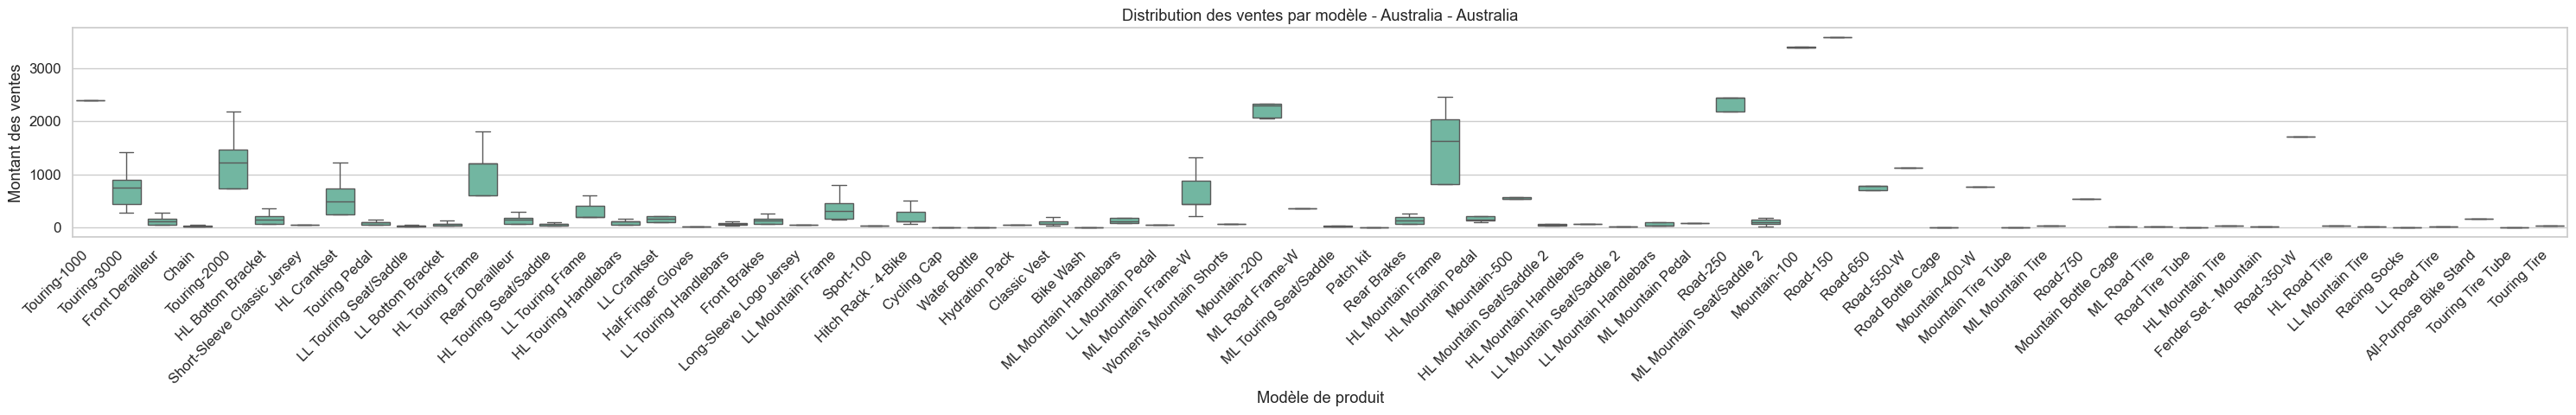

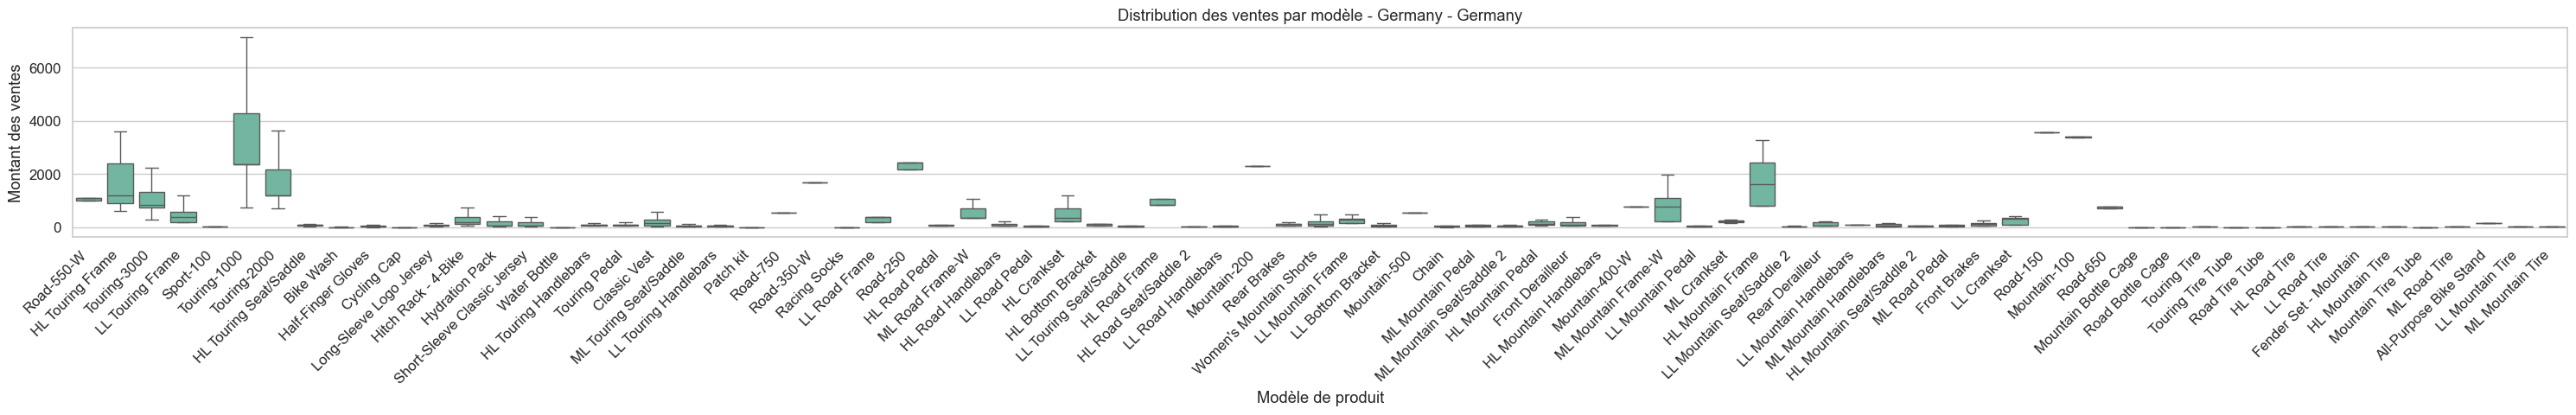

In [183]:
df = sales.merge(products, on="ProductKey", how="left")
df = df.merge(territories, on="SalesTerritoryKey", how="left")
df["Territoire"] = df["Country"] + " - " + df["Region"]

df = df.dropna(subset=["Territoire", "Model", "Sales Amount"])

for territoire in df["Territoire"].unique():
    donnees = df[df["Territoire"] == territoire]

    plt.figure(figsize=(30, 5))

    sns.boxplot(
        data=donnees,
        x="Model",
        y="Sales Amount",
        showfliers=False
    )

    plt.title(f"Distribution des ventes par modèle - {territoire}")
    plt.xlabel("Modèle de produit")
    plt.ylabel("Montant des ventes")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

Personnalisez les graphiques en ajoutant des titres, étiquettes et légendes : </br>
-Personnalisez la police </br>
-Personnalisez le thème de couleurs </br>
-Ajoutez des informations de valeur sur les barres des diagrammes

In [184]:
sns.set_theme(
    style="whitegrid",
    palette="Set2",
    font="Arial",
    font_scale=1.1
)

Affichez une heat map (carte de chaleur ou matrice de corrélation) pour visualiser les corrélations entre les variables : </br>
-Entre le total de vente et la marge

<Axes: >

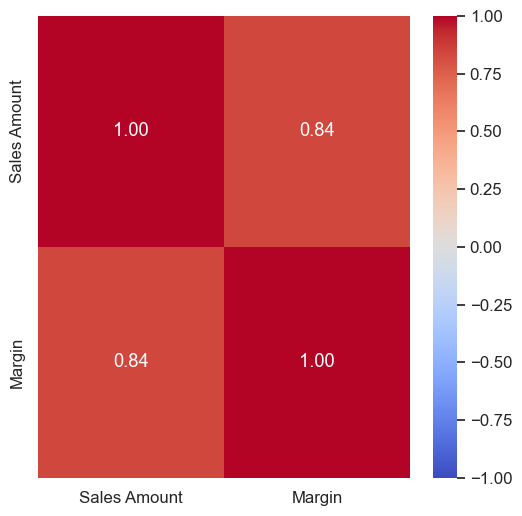

In [185]:
df = sales.merge(products, on="ProductKey", how="left")

ventes_marge = (
    df.groupby("Model", as_index=False)
      .agg({
          "Sales Amount": "sum",
          "Margin": "sum"
      })
)

corr = ventes_marge[["Sales Amount", "Margin"]].corr()

plt.figure(figsize=(6, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

Créez des graphiques en secteur (pie) pour visualiser la part de marché des différents produits ou territoires. Affichez la part en pourcent et/ou en dollars dans les secteurs si possible.

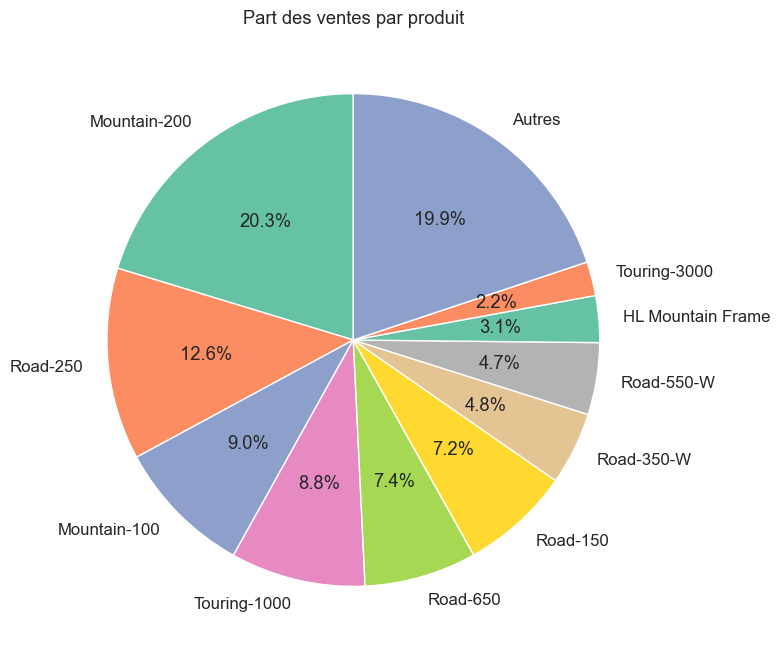

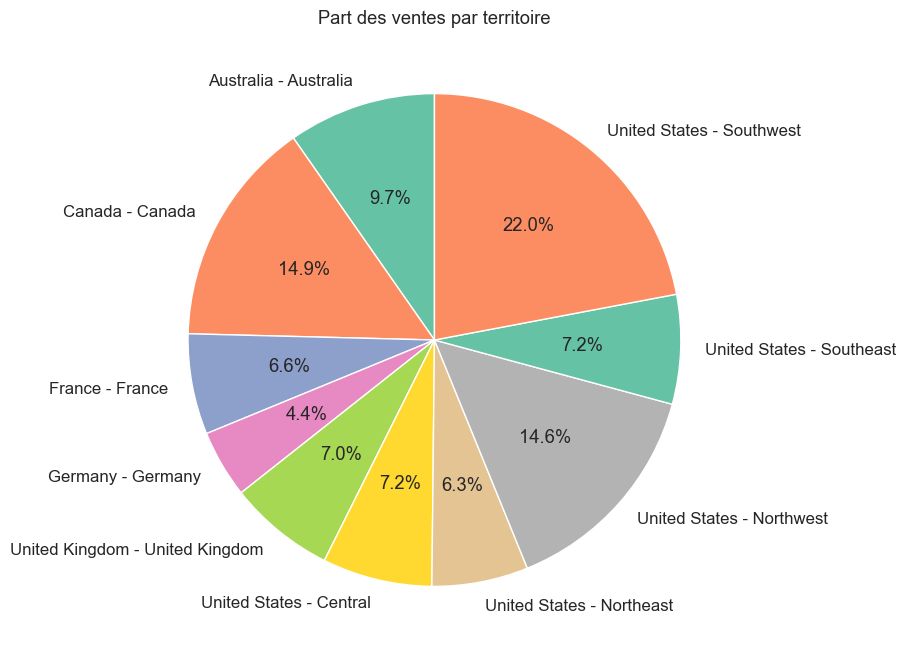

In [186]:
df = sales.merge(products, on="ProductKey", how="left")

ventes_produit = (
    df.groupby("Model")["Sales Amount"]
    .sum()
    .sort_values(ascending=False)
)

top_10 = ventes_produit.head(10)

non_top_10 = ventes_produit.iloc[10:].sum()

ventes_finales = pd.concat([
    top_10,
    pd.Series({"Autres": non_top_10})
])

plt.figure(figsize=(8, 8))
plt.pie(
    ventes_finales,
    labels=ventes_finales.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Part des ventes par produit")
plt.show()

df = sales.merge(territories, on="SalesTerritoryKey", how="left")
df["Territoire"] = df["Country"] + " - " + df["Region"]

ventes_territoire = (
    df.groupby("Territoire")["Sales Amount"]
    .sum()
)

plt.figure(figsize=(8, 8))
plt.pie(
    ventes_territoire,
    labels=ventes_territoire.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Part des ventes par territoire")
plt.show()

# 7. Analyse Temporelle des Ventes

Analysez les ventes par mois et créez une série temporelle (dont les Index sont des dates).

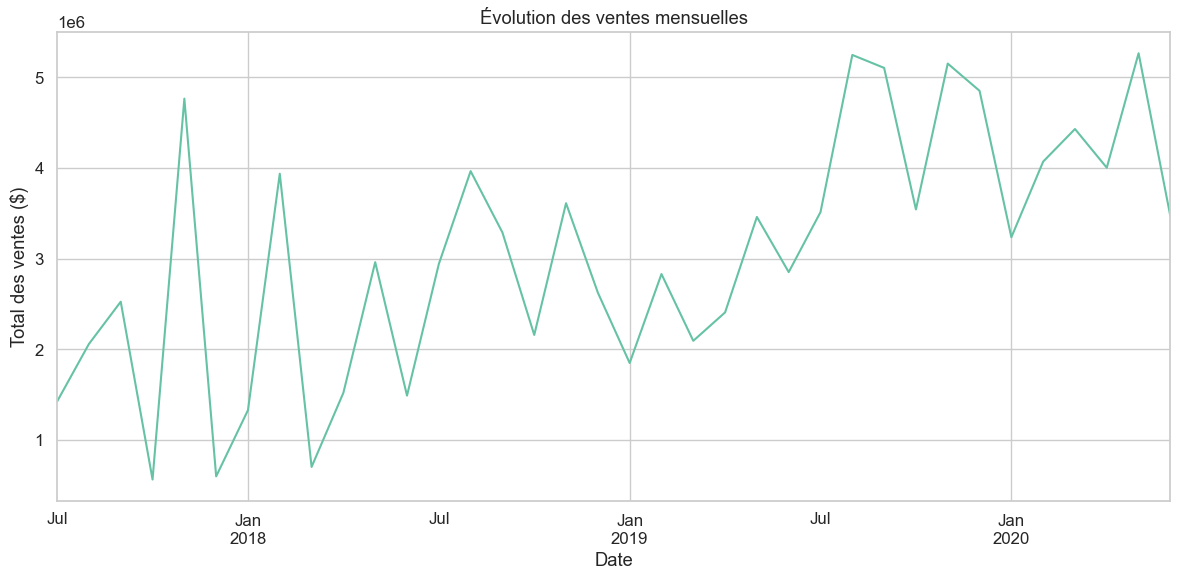

In [187]:
df = sales.merge(dates, left_on="OrderDateKey", right_on="DateKey", how="left")

ventes_mois = (
    df.set_index("Date")["Sales Amount"]
      .resample("ME")
      .sum()
)

ventes_mois.plot(figsize=(12, 6))

plt.title("Évolution des ventes mensuelles")
plt.xlabel("Date")
plt.ylabel("Total des ventes ($)")
plt.grid(True)
plt.tight_layout()
plt.show()

Analysez les ventes par trimestre et par année.

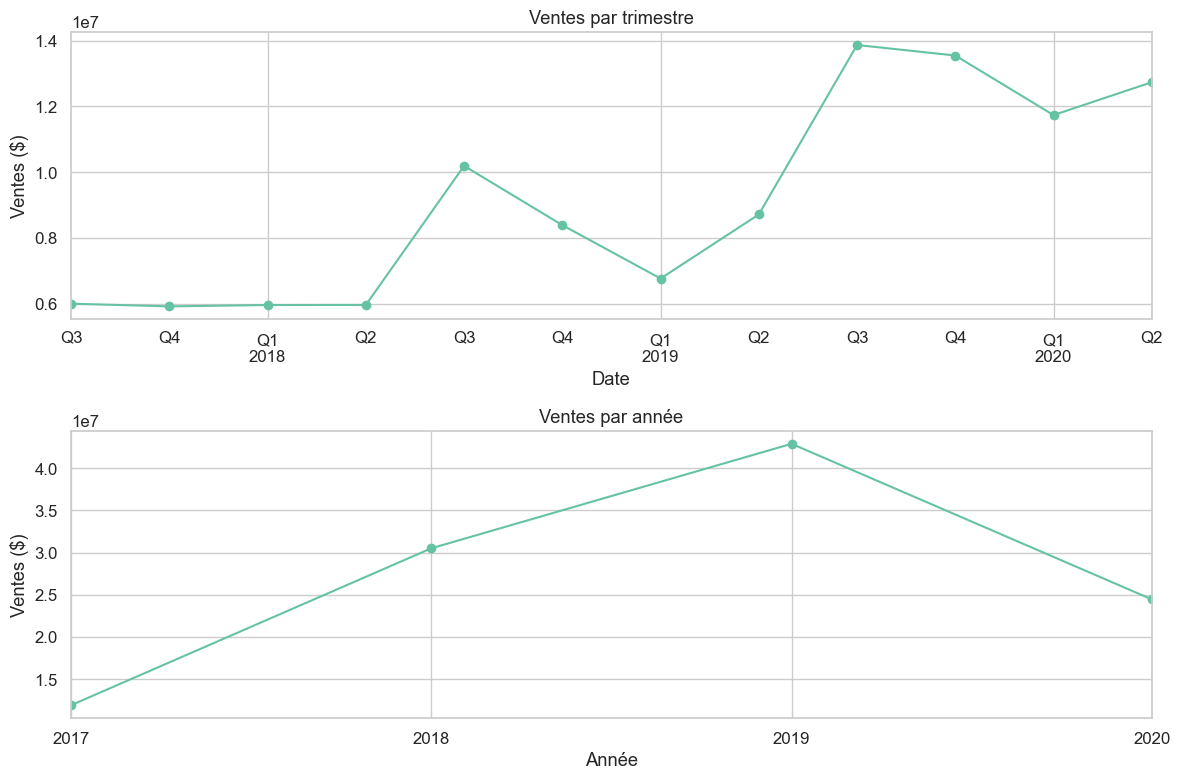

In [188]:
ventes_trimestre = (
    df.set_index("Date")["Sales Amount"]
      .resample("QE")
      .sum()
)

ventes_annee = (
    df.set_index("Date")["Sales Amount"]
      .resample("YE")
      .sum()
)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

ventes_trimestre.plot(ax=axes[0], marker="o")
axes[0].set_title("Ventes par trimestre")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Ventes ($)")
axes[0].grid(True)

ventes_annee.plot(ax=axes[1], marker="o")
axes[1].set_title("Ventes par année")
axes[1].set_xlabel("Année")
axes[1].set_ylabel("Ventes ($)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

Visualisez les tendances des ventes au fil du temps avec des graphiques de séries temporelles (ex. bougies)

# 8. Fusion des Données pour une Analyse Globale

Fusionnez les différentes tables de données pour obtenir une vue complète des ventes.

In [189]:
df = sales.merge(products, on="ProductKey", how="left")
df = df.merge(customers, on="CustomerKey", how="left")
df = df.merge(territories, on="SalesTerritoryKey", how="left")
df = df.merge(dates, left_on="OrderDateKey", right_on="DateKey",  how="left")


print(df.head())
print(df.shape)

   SalesOrderLineKey  ResellerKey  CustomerKey  ProductKey  OrderDateKey  DueDateKey  ...       Date  Fiscal Year  Fiscal Quarter     Month     Full Date  MonthKey
0           43659001          676           -1         349      20170702    20170712  ... 2017-07-02       FY2018       FY2018 Q1  2017 Jul  2017 Jul, 02    201707
1           43659002          676           -1         350      20170702    20170712  ... 2017-07-02       FY2018       FY2018 Q1  2017 Jul  2017 Jul, 02    201707
2           43659003          676           -1         351      20170702    20170712  ... 2017-07-02       FY2018       FY2018 Q1  2017 Jul  2017 Jul, 02    201707
3           43659004          676           -1         344      20170702    20170712  ... 2017-07-02       FY2018       FY2018 Q1  2017 Jul  2017 Jul, 02    201707
4           43659005          676           -1         345      20170702    20170712  ... 2017-07-02       FY2018       FY2018 Q1  2017 Jul  2017 Jul, 02    201707

[5 rows x 41 co

Vérifiez bien que toutes les lignes de la table des ventes sont présentes dans le résultat.

In [190]:
print("Lignes dans sales :", len(sales))
print("Lignes dans df :", len(df))

Lignes dans sales : 121253
Lignes dans df : 121253


Réalisez une analyse croisée des données : </br>
-Ventes par produit et par territoire, </br>
-Nombre de produits par modèle, </br>
-Clients avec le plus de commandes, </br>
-Clients ayants le plus dépensé, </br>
-Nombre de ventes par catégorie de produit par territoire

In [191]:
df = sales.merge(products, on="ProductKey", how="left")
df = df.merge(territories, on="SalesTerritoryKey", how="left")
df = df.merge(customers, on="CustomerKey", how="left")

ventes_produit_territoire = pd.pivot_table(
    df,
    index="Model",
    columns="Country",
    values="Sales Amount",
    aggfunc="sum",
    fill_value=0
)

display(ventes_produit_territoire)

produits_modele = (
    df.groupby("Model")["ProductKey"]
    .nunique()
    .reset_index(name="Nombre de produits")
)

display(produits_modele)

commandes_clients = (
    df.groupby(["CustomerKey","Customer"])["SalesOrderLineKey"]
    .nunique()
    .reset_index(name="Nombre de commandes")
    .sort_values("Nombre de commandes", ascending=False)
)

display(commandes_clients.head(10))

depenses_clients = (
    df.groupby(["CustomerKey","Customer"])["Sales Amount"]
    .sum()
    .reset_index(name="Total dépensé")
    .sort_values("Total dépensé", ascending=False)
)

display(depenses_clients.head(10))

ventes_categorie_territoire = pd.pivot_table(
    df,
    index="Category",
    columns="Country",
    values="SalesOrderLineKey",
    aggfunc="count",
    fill_value=0
)

display(ventes_categorie_territoire)

Country,Australia,Canada,France,Germany,United Kingdom,United States
Model,,,,,,
All-Purpose Bike Stand,"10,335.00","5,088.00","3,021.00","3,180.00","4,452.00","13,515.00"
Bike Wash,"2,286.42","3,268.60","1,459.58","1,378.69","1,587.97","8,425.73"
Cable Lock,0.00,"4,210.24","1,050.00",0.00,735.00,"10,229.98"
Chain,850.08,"1,141.54","1,231.65",522.19,660.25,"4,972.00"
Classic Vest,"21,065.62","48,102.10","23,613.38","23,050.42","22,036.20","121,620.66"
...,...,...,...,...,...,...
Touring-2000,"270,668.58","211,383.90","235,781.98","222,381.21","212,994.31","979,901.90"
Touring-3000,"347,310.30","277,022.75","284,640.45","309,472.65","239,422.65","989,508.46"
Water Bottle,"4,314.35","4,382.63","2,370.64","2,765.78","3,005.45","11,815.31"


,Model,Nombre de produits
0,All-Purpose Bike Stand,1
1,Bike Wash,1
2,Cable Lock,1
3,Chain,1
4,Classic Vest,3
...,...,...
102,Touring-2000,4
103,Touring-3000,10
104,Water Bottle,1
105,Women's Mountain Shorts,3


,CustomerKey,Customer,Nombre de commandes
0,-1,[Not Applicable],60855
186,11185,Ashley Henderson,68
301,11300,Fernando Barnes,67
278,11277,Charles Jackson,65
263,11262,Jennifer Simmons,63
288,11287,Henry Garcia,62
177,11176,Mason Roberts,60
92,11091,Dalton Perez,59
567,11566,April Shan,58
332,11331,Samantha Jenkins,58


,CustomerKey,Customer,Total dépensé
0,-1,[Not Applicable],"80,450,596.98"
1302,12301,Nichole Nara,"13,295.38"
1133,12132,Kaitlyn Henderson,"13,294.27"
1309,12308,Margaret He,"13,269.27"
1132,12131,Randall Dominguez,"13,265.99"
1301,12300,Adriana Gonzalez,"13,242.70"
1322,12321,Rosa Hu,"13,215.65"
1125,12124,Brandi Gill,"13,195.64"
1308,12307,Brad She,"13,173.19"
1297,12296,Francisco Sara,"13,164.64"


Country,Australia,Canada,France,Germany,United Kingdom,United States
Category,,,,,,
Accessories,7178,6392,3668,3518,4392,16045
Bikes,5241,5366,2618,2229,3185,21366
Clothing,2152,3872,1577,1180,1750,10837
Components,487,3434,1225,537,1099,11905


Complétez les visualisations précédentes pour représenter les ventes globales par différentes dimensions (produit, territoire, période).

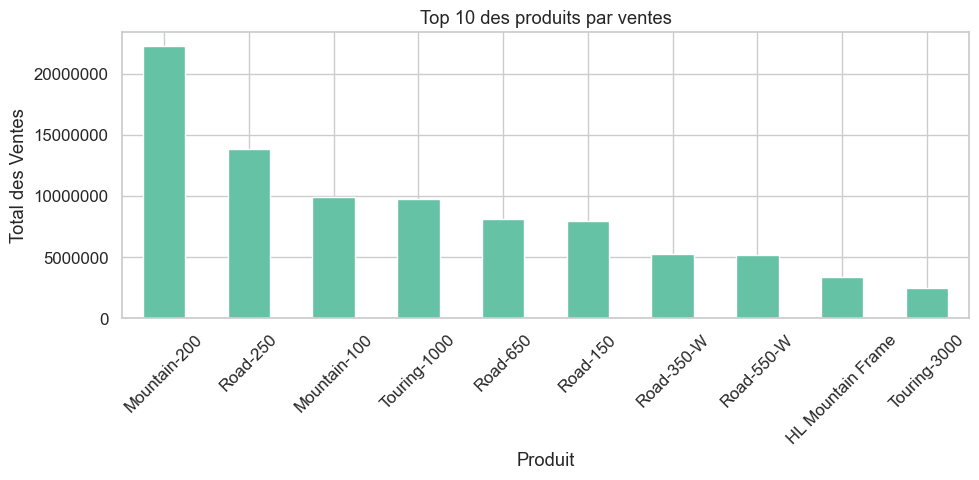

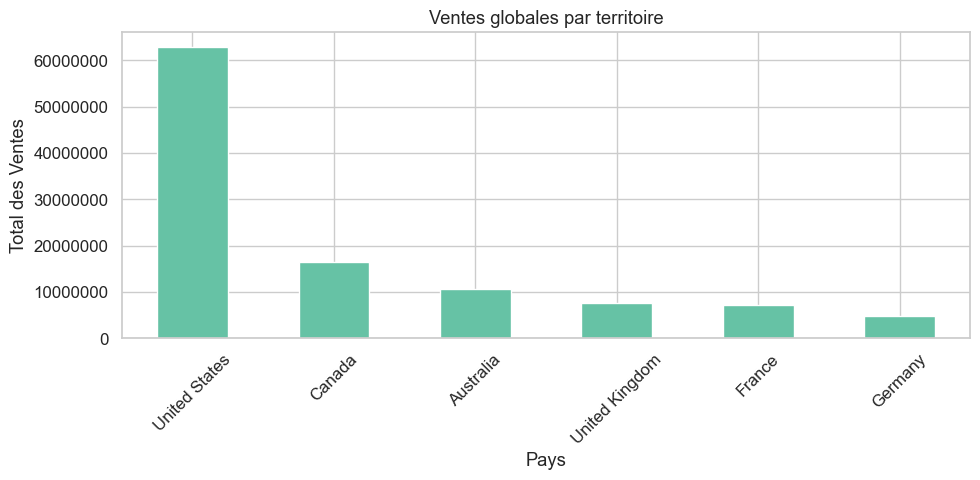

In [192]:
df = sales.merge(products, on="ProductKey", how="left")
df = df.merge(territories, on="SalesTerritoryKey", how="left")
df = df.merge(customers, on="CustomerKey", how="left")

ventes_produit = (
    df.groupby("Model")["Sales Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

ventes_produit.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 des produits par ventes")
plt.ticklabel_format(style='plain', axis='y')
plt.xlabel("Produit")
plt.ylabel("Total des Ventes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


ventes_territoire = (
    df.groupby("Country")["Sales Amount"]
    .sum()
    .sort_values(ascending=False)
)

ventes_territoire.plot(kind="bar", figsize=(10, 5))

plt.ticklabel_format(style='plain', axis='y')
plt.title("Ventes globales par territoire")
plt.xlabel("Pays")
plt.ylabel("Total des Ventes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 9. Analyse des Performances des Revendeurs

Analysez les ventes par revendeur et identifiez les revendeurs les plus performants.

In [193]:
df = sales.merge(resellers, on="ResellerKey", how="left")

ventes_revendeur = (
    df.groupby(["ResellerKey","Reseller"])["Sales Amount"]
    .sum()
    .reset_index(name="Total des ventes")
    .sort_values("Total des ventes", ascending=False)
    .head(20)
)

display(ventes_revendeur)

,ResellerKey,Reseller,Total des ventes
0,-1,[Not Applicable],"29,358,677.22"
631,697,Brakes and Gears,"877,107.19"
158,170,Excellent Riding Supplies,"853,849.18"
613,678,Vigorous Exercise Company,"841,908.77"
305,328,Totes & Baskets Company,"816,755.58"
462,514,Retail Mall,"799,277.90"
144,155,Corner Bicycle Supply,"787,773.04"
66,72,Outdoor Equipment Store,"746,317.53"
390,433,Thorough Parts and Repair Services,"740,985.83"
208,227,"Health Spa, Limited","730,798.71"


Visualisez les performances des revendeurs avec des graphiques à barres et des diagrammes circulaires.

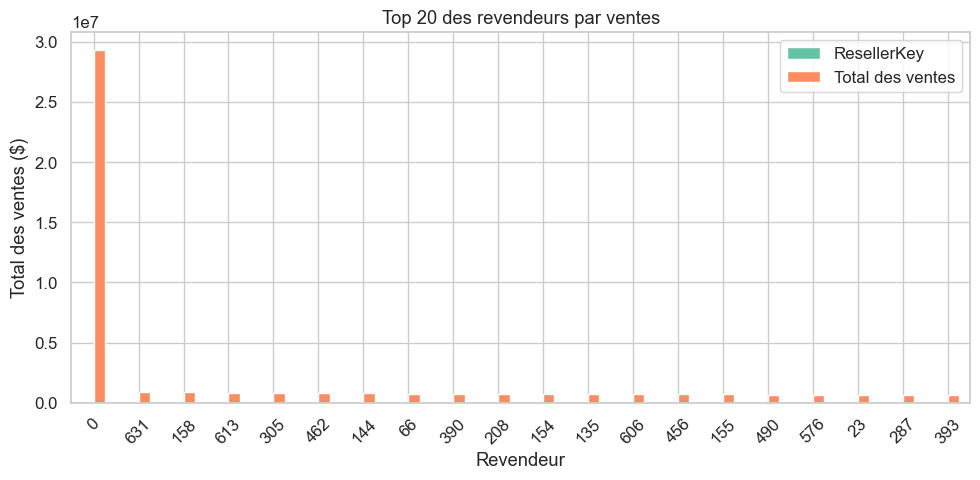

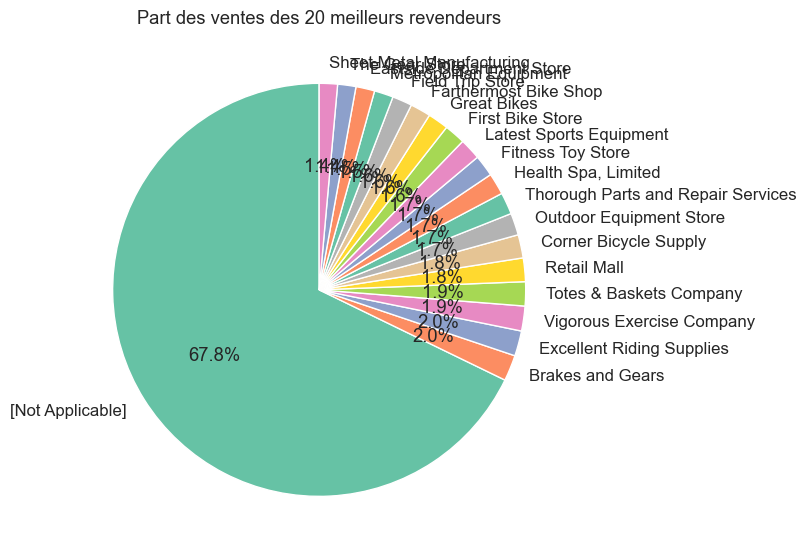

In [194]:
ventes_revendeur.plot(kind="bar", figsize=(10, 5))

plt.title("Top 20 des revendeurs par ventes")
plt.xlabel("Revendeur")
plt.ylabel("Total des ventes ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 8))
plt.pie(
    ventes_revendeur["Total des ventes"],
    labels=ventes_revendeur["Reseller"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Part des ventes des 20 meilleurs revendeurs")
plt.tight_layout()
plt.show()

Comparez les performances des revendeurs sur différentes périodes.

Année,2017,2018,2019,2020
Reseller,,,,
Brakes and Gears,"88,003.66","247,559.40","361,627.85","179,916.29"
Corner Bicycle Supply,"66,495.98","288,884.07","315,833.45","116,559.55"
Eastside Department Store,0.00,"208,261.62","309,514.91","118,449.94"
Excellent Riding Supplies,"73,842.73","317,507.39","323,324.43","139,174.63"
Farthermost Bike Shop,"74,349.51","328,362.94","237,193.84","53,596.20"
Field Trip Store,0.00,"116,789.48","368,440.99","186,387.56"
First Bike Store,"38,099.42","236,445.56","308,893.80","128,425.99"
Fitness Toy Store,"76,086.19","276,086.15","297,219.90","77,880.41"
Great Bikes,"55,186.21","247,370.31","249,537.33","148,709.93"


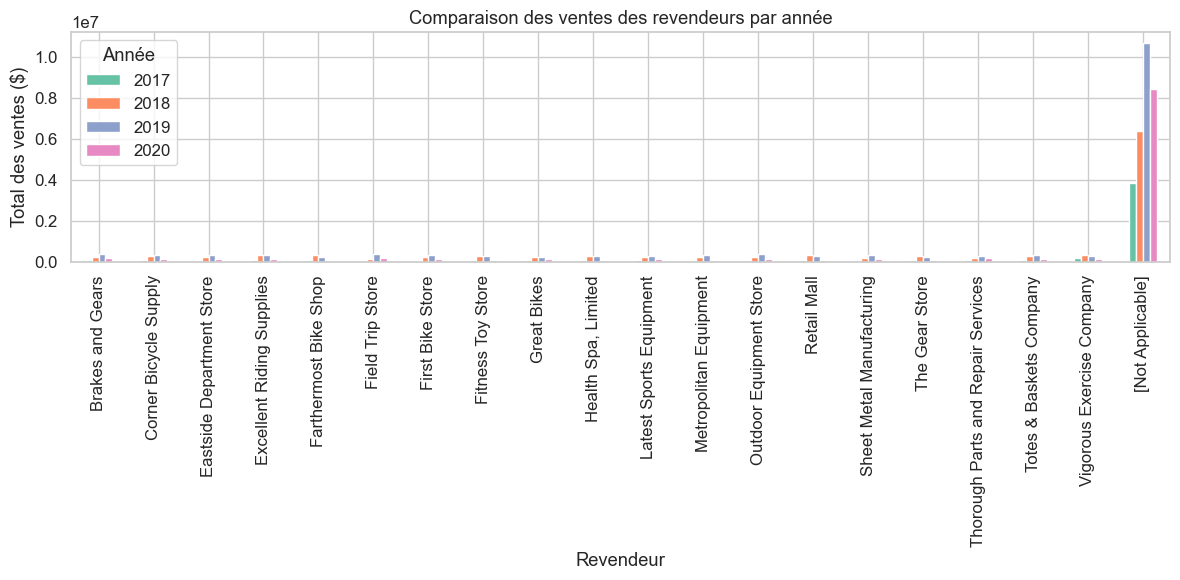

In [195]:
df = sales.merge(resellers, on="ResellerKey", how="left")
df = df.merge(
    dates,
    left_on="OrderDateKey",
    right_on="DateKey",
    how="left"
)

df["Année"] = df["Date"].dt.year

ventes_revendeur = (
    df.groupby(["ResellerKey","Reseller"])["Sales Amount"]
    .sum()
    .reset_index(name="Total des ventes")
    .sort_values("Total des ventes", ascending=False)
    .head(20)
)

df_top20 = df[df["ResellerKey"].isin(ventes_revendeur["ResellerKey"])]

ventes_periode = pd.pivot_table(
    df_top20,
    index="Reseller",
    columns="Année",
    values="Sales Amount",
    aggfunc="sum",
    fill_value=0
)

display(ventes_periode)

ventes_periode.plot(kind="bar", figsize=(12, 6))

plt.title("Comparaison des ventes des revendeurs par année")
plt.xlabel("Revendeur")
plt.ylabel("Total des ventes ($)")
plt.legend(title="Année")
plt.tight_layout()
plt.show()